In [2]:
import anndata as ad
import re
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
from scipy import sparse
from scib_metrics.nearest_neighbors import pynndescent
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score


# st_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/cosmx_nsclc_Lung5-Rep1_adata_annotated_med_with_admix_probs.h5ad')
# sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/scRNA-seq/adata/GSE127465_tumor_integrated.h5ad')
# sc_data = ad.concat([ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_val_med_with_admix_probs.h5ad'),
#                     ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_train_med_with_admix_probs.h5ad')],
#                     join='outer')
# sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_train_med_with_admix_probs.h5ad')
# sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_hardcap_100th_train_med_with_admix_probs.h5ad')


sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_hardcap_val_med_with_admix_probs.h5ad')


KeyboardInterrupt: 

In [ ]:
count_vals = np.unique(sc_data.X.toarray().flatten())
count_vals.sort()
print(count_vals)

In [100]:
from tqdm.notebook import tqdm
tissue_key = 'harmony_spatial_tissue'
tissues = pd.Series(sc_data.obs[tissue_key].dropna().unique()).sort_values().to_list()
tissues

['Lung5_Rep1',
 'Lung5_Rep2',
 'Lung5_Rep3',
 'Lung6',
 'Lung9_Rep1',
 'Lung9_Rep2',
 'Lung12',
 'Lung13']

In [101]:
label_key = 'cell_type'
tissue_key = 'harmony_spatial_tissue'
target_removed_fractions = [0.01, 0.02, 0.05, 0.1, 0.15]
leiden_resolution = 1.0
leiden_optimize_resolution = False
leiden_n_neighbors = 15
n_pcs = 50
library_size_target_sum = 1e4
n_jobs = 1
random_state = 0

import numpy as np
from scipy import sparse

def threshold_for_removed_fraction(probs, X, target_removed_frac: float):
    """
    Choose thr so that removing entries with probs >= thr removes ~target_removed_frac
    of TOTAL transcript counts (sum of counts), considering only X>0 entries.

    Returns
    -------
    thr : float
    achieved : float  (fraction of transcript counts removed using probs >= thr)
    """
    r = float(target_removed_frac)
    r = min(max(r, 0.0), 1.0)
    if r == 0.0:
        return np.inf, 0.0
    if r == 1.0:
        return -np.inf, 1.0

    # Pull (pvals, counts) only where X>0
    if sparse.issparse(X):
        Xcoo = X.tocoo()
        counts = Xcoo.data.astype(float)
        pvals = np.asarray(probs[Xcoo.row, Xcoo.col]).ravel().astype(float)
    else:
        X = np.asarray(X)
        probs = np.asarray(probs)
        nz = X > 0
        counts = X[nz].astype(float)
        pvals = probs[nz].astype(float)

    good = np.isfinite(pvals) & np.isfinite(counts) & (counts > 0)
    pvals = pvals[good]
    counts = counts[good]
    if counts.size == 0:
        raise ValueError("No expressed transcripts found (X>0).")

    total = float(counts.sum())
    target = r * total

    # Sort by probability descending, accumulate transcript counts
    order = np.argsort(pvals)[::-1]
    p_sorted = pvals[order]
    c_sorted = counts[order]
    cum = np.cumsum(c_sorted)

    idx = int(np.searchsorted(cum, target, side="left"))
    idx = min(idx, len(p_sorted) - 1)
    thr = float(p_sorted[idx])

    # Achieved fraction if you remove probs >= thr (important!)
    removed = float(c_sorted[p_sorted >= thr].sum())
    achieved = removed / total

    return thr, achieved

def _prepare_matrix_and_labels(X, labels, make_dense=False):
    labels = pd.Series(labels).astype('category')
    valid = ~labels.isna().to_numpy()
    X = X[valid]
    labels = labels[valid].cat.remove_unused_categories()
    if make_dense and sparse.issparse(X):
        X = X.toarray()
    return X, labels.to_numpy()


def _obsm_key_for_case(case_name):
    safe_case_name = re.sub(r'[^0-9A-Za-z_]+', '_', case_name).strip('_')
    return f'X_pca_metric_{safe_case_name}'


def _store_preprocessed_pcs(adata, obs_names, obsm_key, X_preprocessed):
    if obsm_key not in adata.obsm:
        adata.obsm[obsm_key] = np.full((adata.n_obs, n_pcs), np.nan, dtype=np.float32)
    row_idx = adata.obs_names.get_indexer(obs_names)
    if np.any(row_idx < 0):
        missing = obs_names[row_idx < 0].tolist()
        raise KeyError(f'Observations missing from result AnnData: {missing[:5]}')
    stored = adata.obsm[obsm_key]
    stored[row_idx, : X_preprocessed.shape[1]] = X_preprocessed.astype(np.float32, copy=False)
    adata.obsm[obsm_key] = stored


def preprocess_counts_for_metrics(X):
    adata = ad.AnnData(X=X.copy())
    sc.pp.normalize_total(adata, target_sum=library_size_target_sum)
    sc.pp.log1p(adata)
    n_comps = min(n_pcs, adata.n_obs - 1, adata.n_vars - 1)
    if n_comps < 1:
        raise ValueError('PCA metrics require at least two observations and two variables.')
    sc.pp.pca(adata, n_comps=n_comps, random_state=random_state)
    return adata.obsm['X_pca']


def _neighbors_for_scib_leiden_metrics(embedding):
    neighbors = pynndescent(
        embedding,
        n_neighbors=min(leiden_n_neighbors, embedding.shape[0]),
        random_state=random_state,
        n_jobs=n_jobs,
    )
    return neighbors


def cleaned_admixed_counts(adata, thresh):
    admixed = adata.X + adata.layers['admixed_counts']
    admix_probs = adata.layers['admix_probs']

    if sparse.issparse(admixed):
        cleaned = admixed.copy()
        row_idx, col_idx = cleaned.nonzero()
        probs_for_nonzero_counts = admix_probs[row_idx, col_idx]
        cleaned.data[np.asarray(probs_for_nonzero_counts).ravel() >= thresh] = 0
        cleaned.eliminate_zeros()
        return cleaned

    if sparse.issparse(admix_probs):
        admix_probs = admix_probs.toarray()

    return np.where(admix_probs >= thresh, 0, admixed)


def score_case(
    tissue,
    case_name,
    X,
    labels,
    result_adata,
    target_removed_fraction=np.nan,
    threshold=np.nan,
    achieved_removed_fraction=np.nan,
):
    valid_obs_names = pd.Index(labels.index)[~pd.Series(labels).isna().to_numpy()]
    X_raw, labels_prepared = _prepare_matrix_and_labels(X, labels)
    X_preprocessed = preprocess_counts_for_metrics(X_raw)
    obsm_key = _obsm_key_for_case(case_name)
    _store_preprocessed_pcs(result_adata, valid_obs_names, obsm_key, X_preprocessed)
    neighbors = _neighbors_for_scib_leiden_metrics(X_preprocessed)
    leiden_metrics = scib_metrics.nmi_ari_cluster_labels_leiden(
        neighbors,
        labels_prepared,
        optimize_resolution=leiden_optimize_resolution,
        resolution=leiden_resolution,
        n_jobs=n_jobs,
        seed=random_state,
    )
    return {
        'tissue': tissue,
        'case': case_name,
        'obsm_key': obsm_key,
        'target_removed_fraction': target_removed_fraction,
        'admix_prob_threshold': threshold,
        'achieved_removed_fraction': achieved_removed_fraction,
        'silhouette_score': silhouette_score(X_preprocessed, labels_prepared, metric='cosine'),
        'calinski_harabasz': calinski_harabasz_score(X_preprocessed, labels_prepared),
        'davies_bouldin': davies_bouldin_score(X_preprocessed, labels_prepared),
        'leiden_nmi_vs_cell_type': leiden_metrics['nmi'],
        'leiden_adjusted_rand_vs_cell_type': leiden_metrics['ari'],
    }


def score_tissue(tissue, adata, result_adata):
    admixed_counts = adata.X + adata.layers['admixed_counts']
    rows = [
        score_case(tissue, 'original_unadmixed', adata.X, adata.obs[label_key], result_adata),
        score_case(tissue, 'admixed', admixed_counts, adata.obs[label_key], result_adata),
    ]

    for target_removed_fraction in target_removed_fractions:
        thresh, achieved_removed_fraction = threshold_for_removed_fraction(
            adata.layers['admix_probs'],
            admixed_counts,
            target_removed_fraction,
        )
        rows.append(
            score_case(
                tissue,
                f'cleaned_admixed_removed_frac_{target_removed_fraction:g}',
                cleaned_admixed_counts(adata, thresh),
                adata.obs[label_key],
                result_adata,
                target_removed_fraction=target_removed_fraction,
                threshold=thresh,
                achieved_removed_fraction=achieved_removed_fraction,
            )
        )

    return rows


metrics_adata = sc_data
tissues = pd.Series(sc_data.obs[tissue_key].dropna().unique()).sort_values().to_list()
metric_rows = []
for tissue in tqdm(tissues):
    tissue_data = sc_data[sc_data.obs[tissue_key] == tissue].copy()
    metric_rows.extend(score_tissue(tissue, tissue_data, metrics_adata))

cell_type_separation = pd.DataFrame(metric_rows)
metrics_adata.uns['cell_type_separation_metrics'] = cell_type_separation

metrics_adata

  0%|          | 0/8 [00:00<?, ?it/s]

AnnData object with n_obs × n_vars = 36607 × 957
    obs: 'species', 'filename', 'sample', 'GSM_ID', 'cell_ID', 'Patient', 'Tissue', 'Barcoding emulsion', 'Library', 'Barcode', 'Total counts', 'Percent counts from mitochondrial genes', 'Most likely LM22 cell type', 'Major cell type', 'Minor subset', 'used_in_NSCLC_all_cells', 'x_NSCLC_all_cells', 'y_NSCLC_all_cells', 'used_in_NSCLC_and_blood_immune', 'x_NSCLC_and_blood_immune', 'y_NSCLC_and_blood_immune', 'used_in_NSCLC_immune', 'x_NSCLC_immune', 'y_NSCLC_immune', 'used_in_NSCLC_non_immune', 'x_NSCLC_non_immune', 'y_NSCLC_non_immune', 'used_in_blood', 'x_blood', 'y_blood', 'Barcode_Library', 'batch', 'cell_type', 'harmony_spatial_tissue', 'harmony_spatial_id', 'st_match_1_id', 'st_match_1_dist', 'st_match_1_x', 'st_match_1_y', 'st_match_2_id', 'st_match_2_dist', 'st_match_2_x', 'st_match_2_y', 'st_match_3_id', 'st_match_3_dist', 'st_match_3_x', 'st_match_3_y', 'sampled_st_id', 'sampled_st_x', 'sampled_st_y', 'selected_match_idx', 'spli

In [102]:
print(cell_type_separation.to_string())

        tissue                               case                                        obsm_key  target_removed_fraction  admix_prob_threshold  achieved_removed_fraction  silhouette_score  calinski_harabasz  davies_bouldin  leiden_nmi_vs_cell_type  leiden_adjusted_rand_vs_cell_type
0   Lung5_Rep1                 original_unadmixed                 X_pca_metric_original_unadmixed                      NaN                   NaN                        NaN          0.153115         212.597577        3.747039                 0.691599                           0.498451
1   Lung5_Rep1                            admixed                            X_pca_metric_admixed                      NaN                   NaN                        NaN          0.138350         197.922952        3.868988                 0.697888                           0.519097
2   Lung5_Rep1  cleaned_admixed_removed_frac_0.01  X_pca_metric_cleaned_admixed_removed_frac_0_01                     0.01              1.000000 

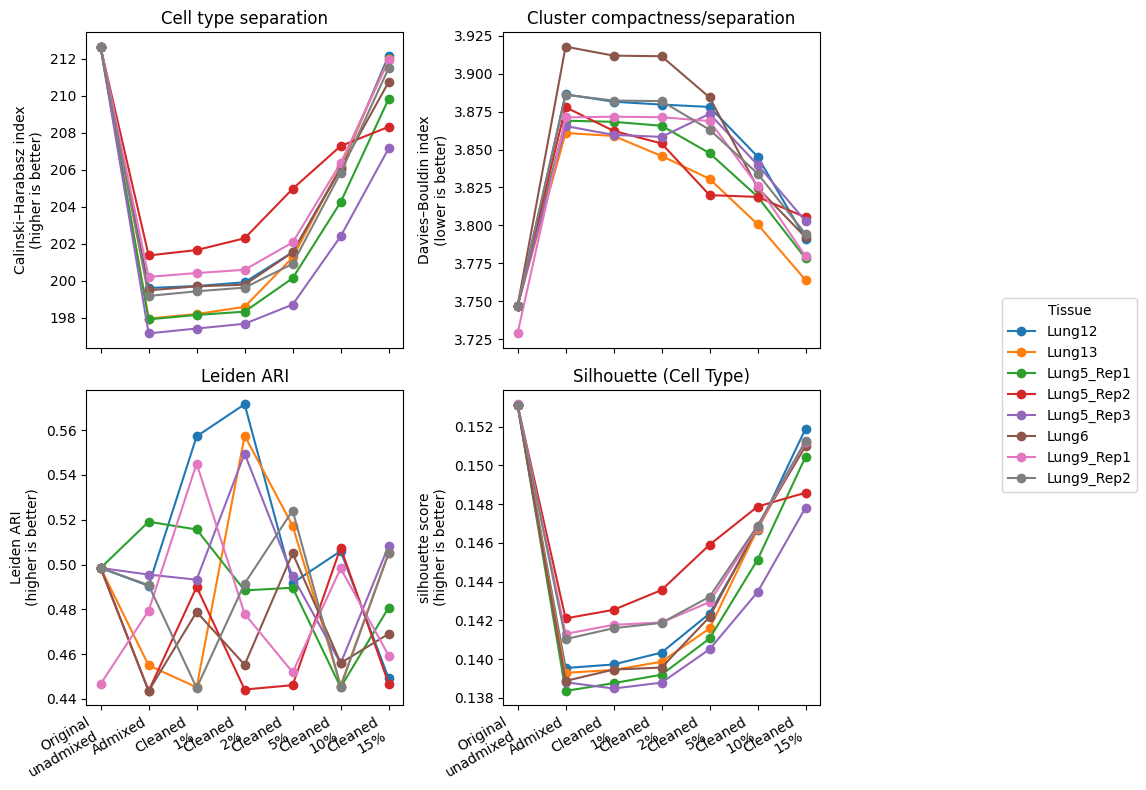

In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# df = your dataframe

plot_df = cell_type_separation.copy()

# Define x-position/order manually
order = [
    "original_unadmixed",
    "admixed",
    "cleaned_admixed_removed_frac_0.01",
    "cleaned_admixed_removed_frac_0.02",
    "cleaned_admixed_removed_frac_0.05",
    "cleaned_admixed_removed_frac_0.1",
    "cleaned_admixed_removed_frac_0.15"
]

labels = [
    "Original\nunadmixed",
    "Admixed",
    "Cleaned\n1%",
    "Cleaned\n2%",
    "Cleaned\n5%",
    "Cleaned\n10%",
    "Cleaned\n15%",
]

label_lookup = dict(zip(order, labels))
plot_df["setting"] = pd.Categorical(plot_df["case"], categories=order, ordered=True)
plot_df = plot_df.sort_values(["tissue", "setting"])
plot_df["x"] = plot_df["setting"].cat.codes

fig, axes_grid = plt.subplots(2, 2, figsize=(10, 8), sharex=True)
axes =  axes_grid.flat


def plot_metric(ax, metric, title, ylabel):
    for tissue, tissue_df in plot_df.groupby("tissue", sort=False):
        ax.plot(tissue_df["x"], tissue_df[metric], marker="o", label=tissue)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(np.arange(len(order)))
    ax.set_xticklabels([label_lookup[case] for case in order], rotation=30, ha="right")


# Calinski-Harabasz
plot_metric(
    axes[0],
    "calinski_harabasz",
    "Cell type separation",
    "Calinski–Harabasz index\n(higher is better)",
)

# Davies-Bouldin
plot_metric(
    axes[1],
    "davies_bouldin",
    "Cluster compactness/separation",
    "Davies–Bouldin index\n(lower is better)",
)

# Leiden ARI
plot_metric(
    axes[2],
    "leiden_adjusted_rand_vs_cell_type",
    "Leiden ARI",
    "Leiden ARI\n(higher is better)",
)

# Silhouette Score
plot_metric(
    axes[3],
    "silhouette_score",
    "Silhouette (Cell Type)",
    "silhouette score\n(higher is better)",
)

# for ax in axes:
#     ax.axvline(1, linestyle="--", linewidth=1, alpha=0.5)
#     ax.grid(True, axis="y", alpha=0.3)

handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="center left", bbox_to_anchor=(1.0, 0.5), title="Tissue")
plt.tight_layout(rect=[0, 0, 0.84, 1])
plt.show()

In [104]:
metrics_adata

AnnData object with n_obs × n_vars = 36607 × 957
    obs: 'species', 'filename', 'sample', 'GSM_ID', 'cell_ID', 'Patient', 'Tissue', 'Barcoding emulsion', 'Library', 'Barcode', 'Total counts', 'Percent counts from mitochondrial genes', 'Most likely LM22 cell type', 'Major cell type', 'Minor subset', 'used_in_NSCLC_all_cells', 'x_NSCLC_all_cells', 'y_NSCLC_all_cells', 'used_in_NSCLC_and_blood_immune', 'x_NSCLC_and_blood_immune', 'y_NSCLC_and_blood_immune', 'used_in_NSCLC_immune', 'x_NSCLC_immune', 'y_NSCLC_immune', 'used_in_NSCLC_non_immune', 'x_NSCLC_non_immune', 'y_NSCLC_non_immune', 'used_in_blood', 'x_blood', 'y_blood', 'Barcode_Library', 'batch', 'cell_type', 'harmony_spatial_tissue', 'harmony_spatial_id', 'st_match_1_id', 'st_match_1_dist', 'st_match_1_x', 'st_match_1_y', 'st_match_2_id', 'st_match_2_dist', 'st_match_2_x', 'st_match_2_y', 'st_match_3_id', 'st_match_3_dist', 'st_match_3_x', 'st_match_3_y', 'sampled_st_id', 'sampled_st_x', 'sampled_st_y', 'selected_match_idx', 'spli

In [105]:
metrics_adata[metrics_adata.obs['cell_type']=='neutrophil'].obs.groupby('Barcode').size().sort_values(ascending=False)

/tmp/ipykernel_3277386/1467981136.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  metrics_adata[metrics_adata.obs['cell_type']=='neutrophil'].obs.groupby('Barcode').size().sort_values(ascending=False)


Barcode
bcEUML    16
bcFGCX    16
bcATEY     8
bcAVJC     8
bcAZMM     8
bcAZVO     8
bcBKIG     8
bcBMVD     8
bcBNKL     8
bcAFAZ     8
bcBOGV     8
bcCDVS     8
bcCKKK     8
bcCEQI     8
bcDGBH     8
bcDHBD     8
bcDIDC     8
bcDCKH     8
bcDVFM     8
bcDXPP     8
bcEGEQ     8
bcEFRC     8
bcEJOD     8
bcEORM     8
bcEQER     8
bcAHSD     8
bcESIW     8
bcEVFL     8
bcFEFL     8
bcFJNK     8
bcFKRV     8
bcFSAR     8
bcFVBY     8
bcFXDM     8
bcFXUT     8
bcGCLU     8
bcGKVT     8
bcGOJT     8
bcGSBI     8
bcGSRU     8
bcGVSN     8
bcGWLF     8
bcHADS     8
bcHBEM     8
bcHBER     8
bcHBPO     8
bcHHLN     8
bcHLHB     8
bcHLHT     8
bcHNOC     8
bcHRWJ     8
bcHTJB     8
bcHUIR     8
bcHXJR     8
bcIBGM     8
bcIFSM     8
bcIHJB     8
bcIIMX     8
dtype: int64

In [109]:
metrics_adata = metrics_adata[((metrics_adata.X>=400).sum(axis=1)==0)&((metrics_adata.layers['admixed_counts']>=400).sum(axis=1)==0)]

/tmp/ipykernel_3277386/2460432501.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  set_adata = set_adata[set_adata.obs.groupby('cell_type').sample(frac=0.1).index]
/tmp/ipykernel_3277386/2460432501.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  set_adata = set_adata[set_adata.obs.groupby('cell_type').sample(frac=0.1).index]
/tmp/ipykernel_3277386/2460432501.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  s

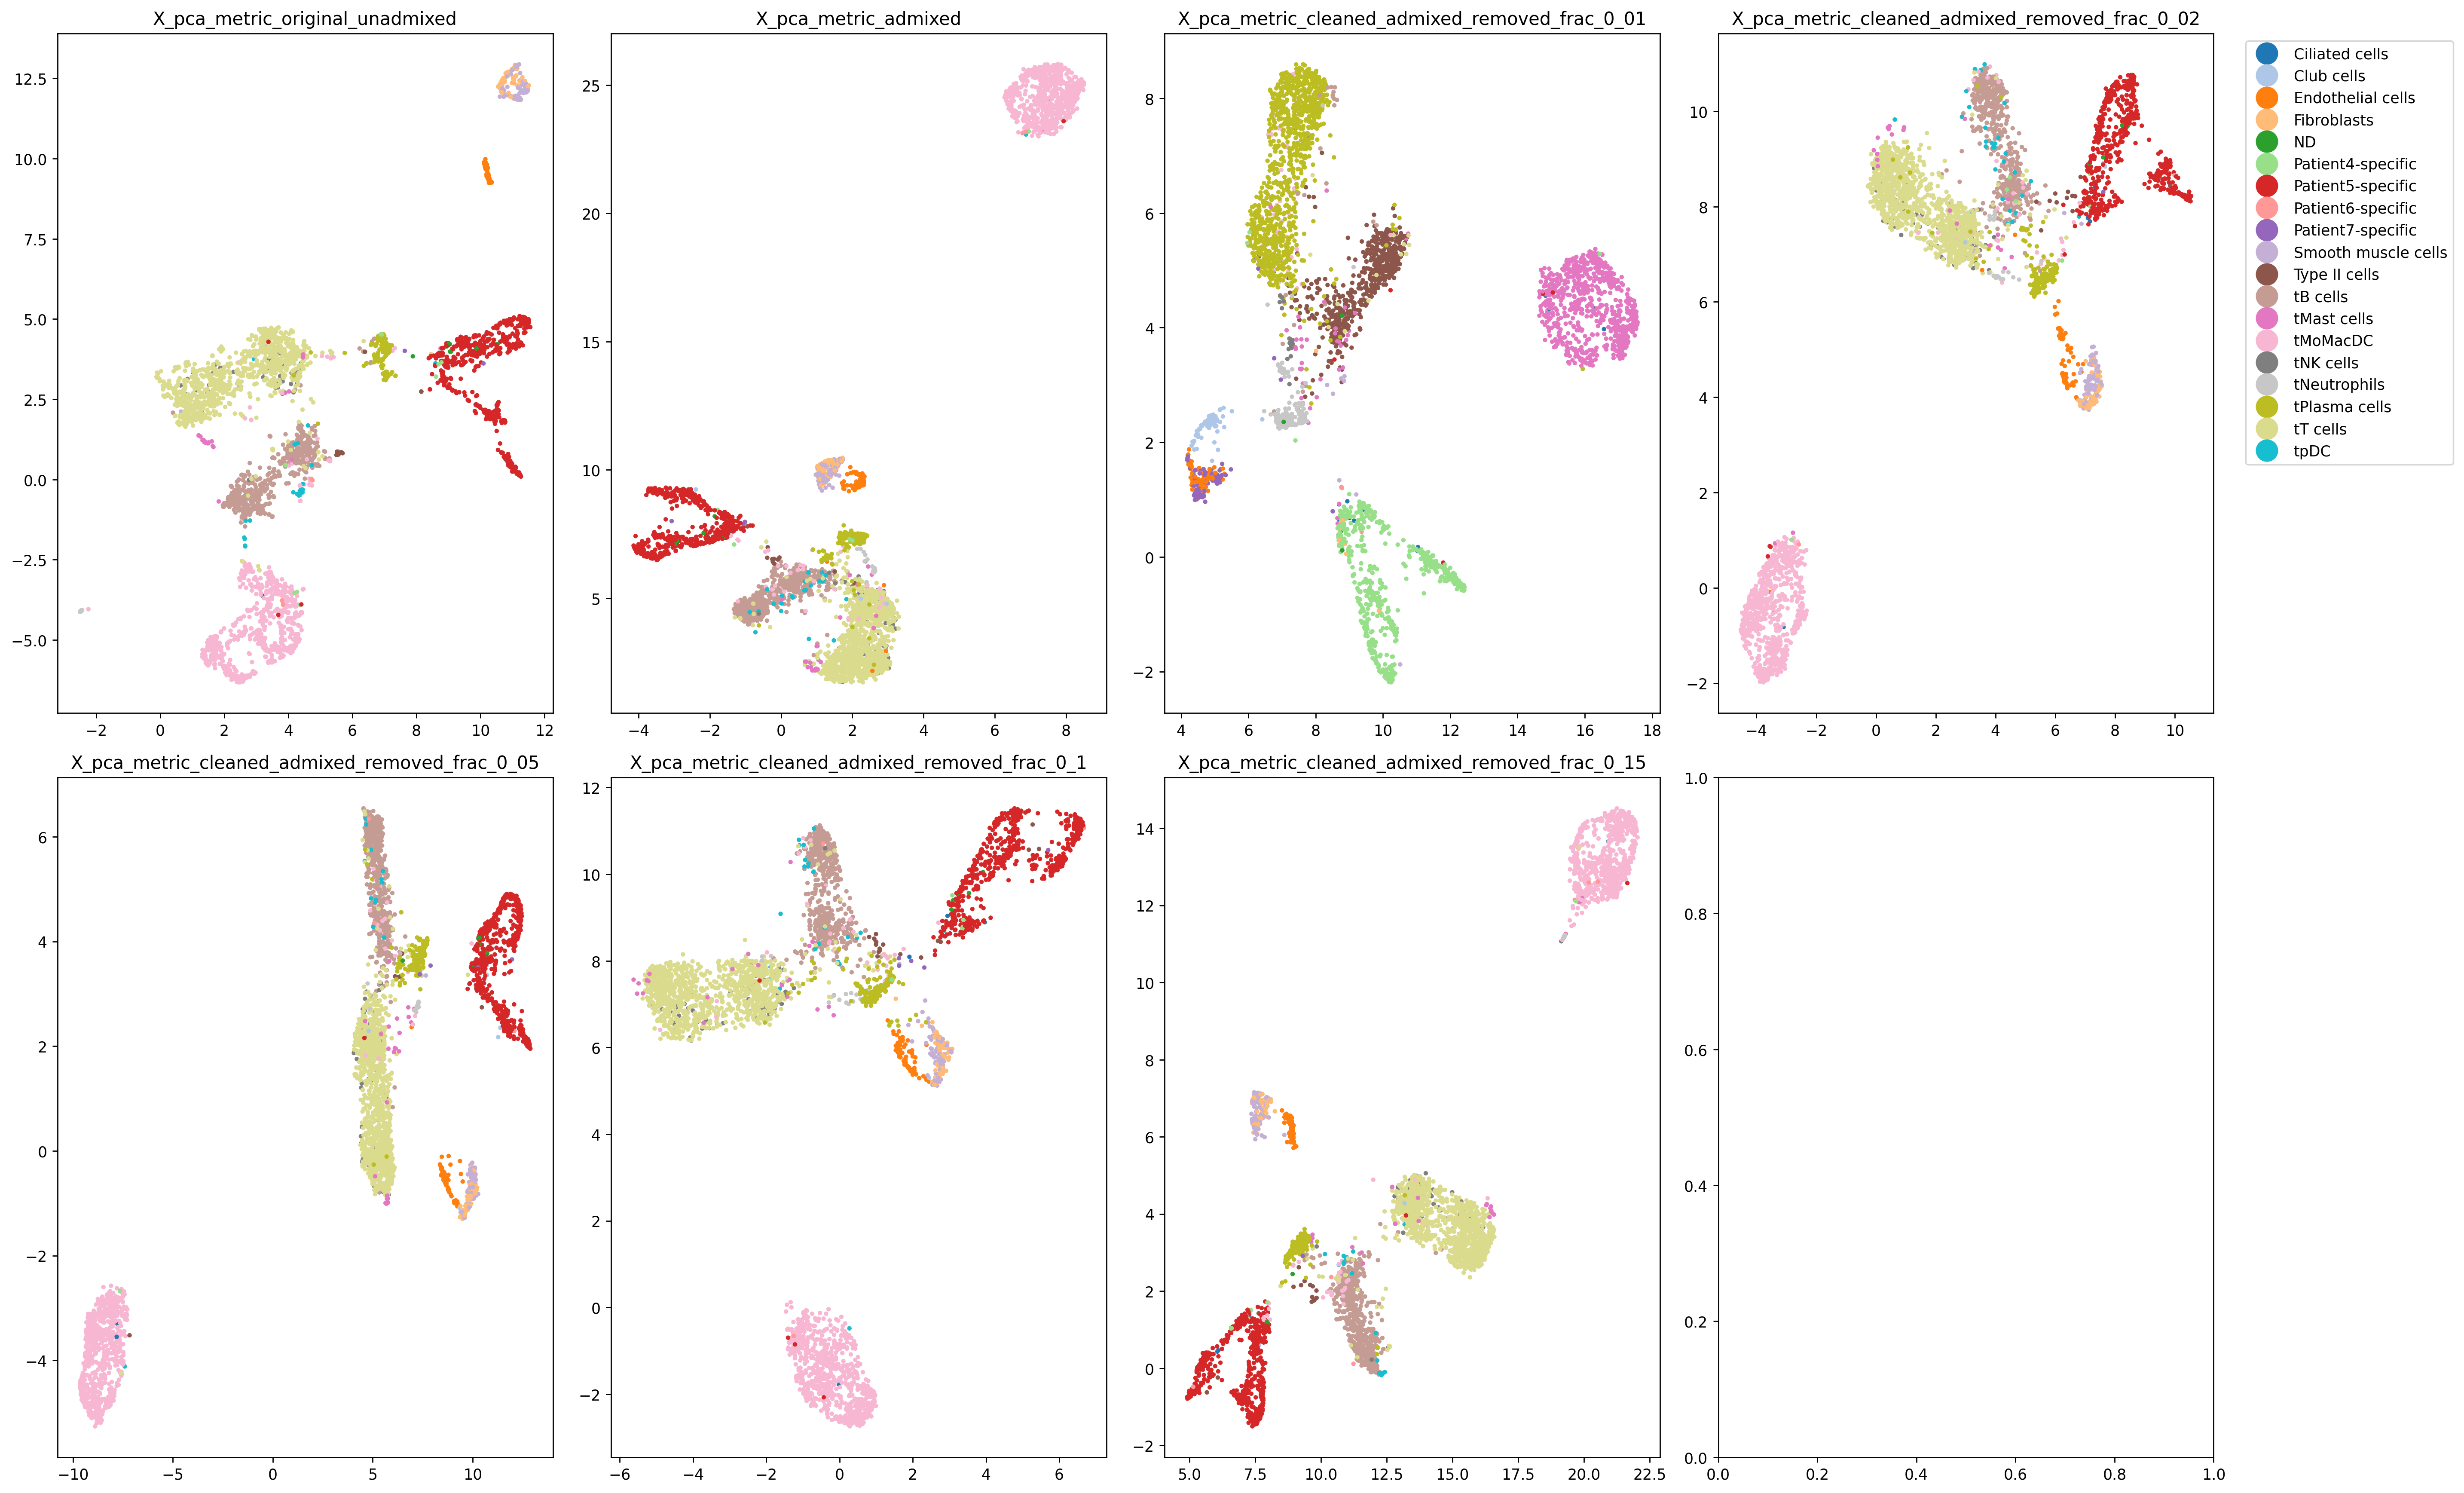

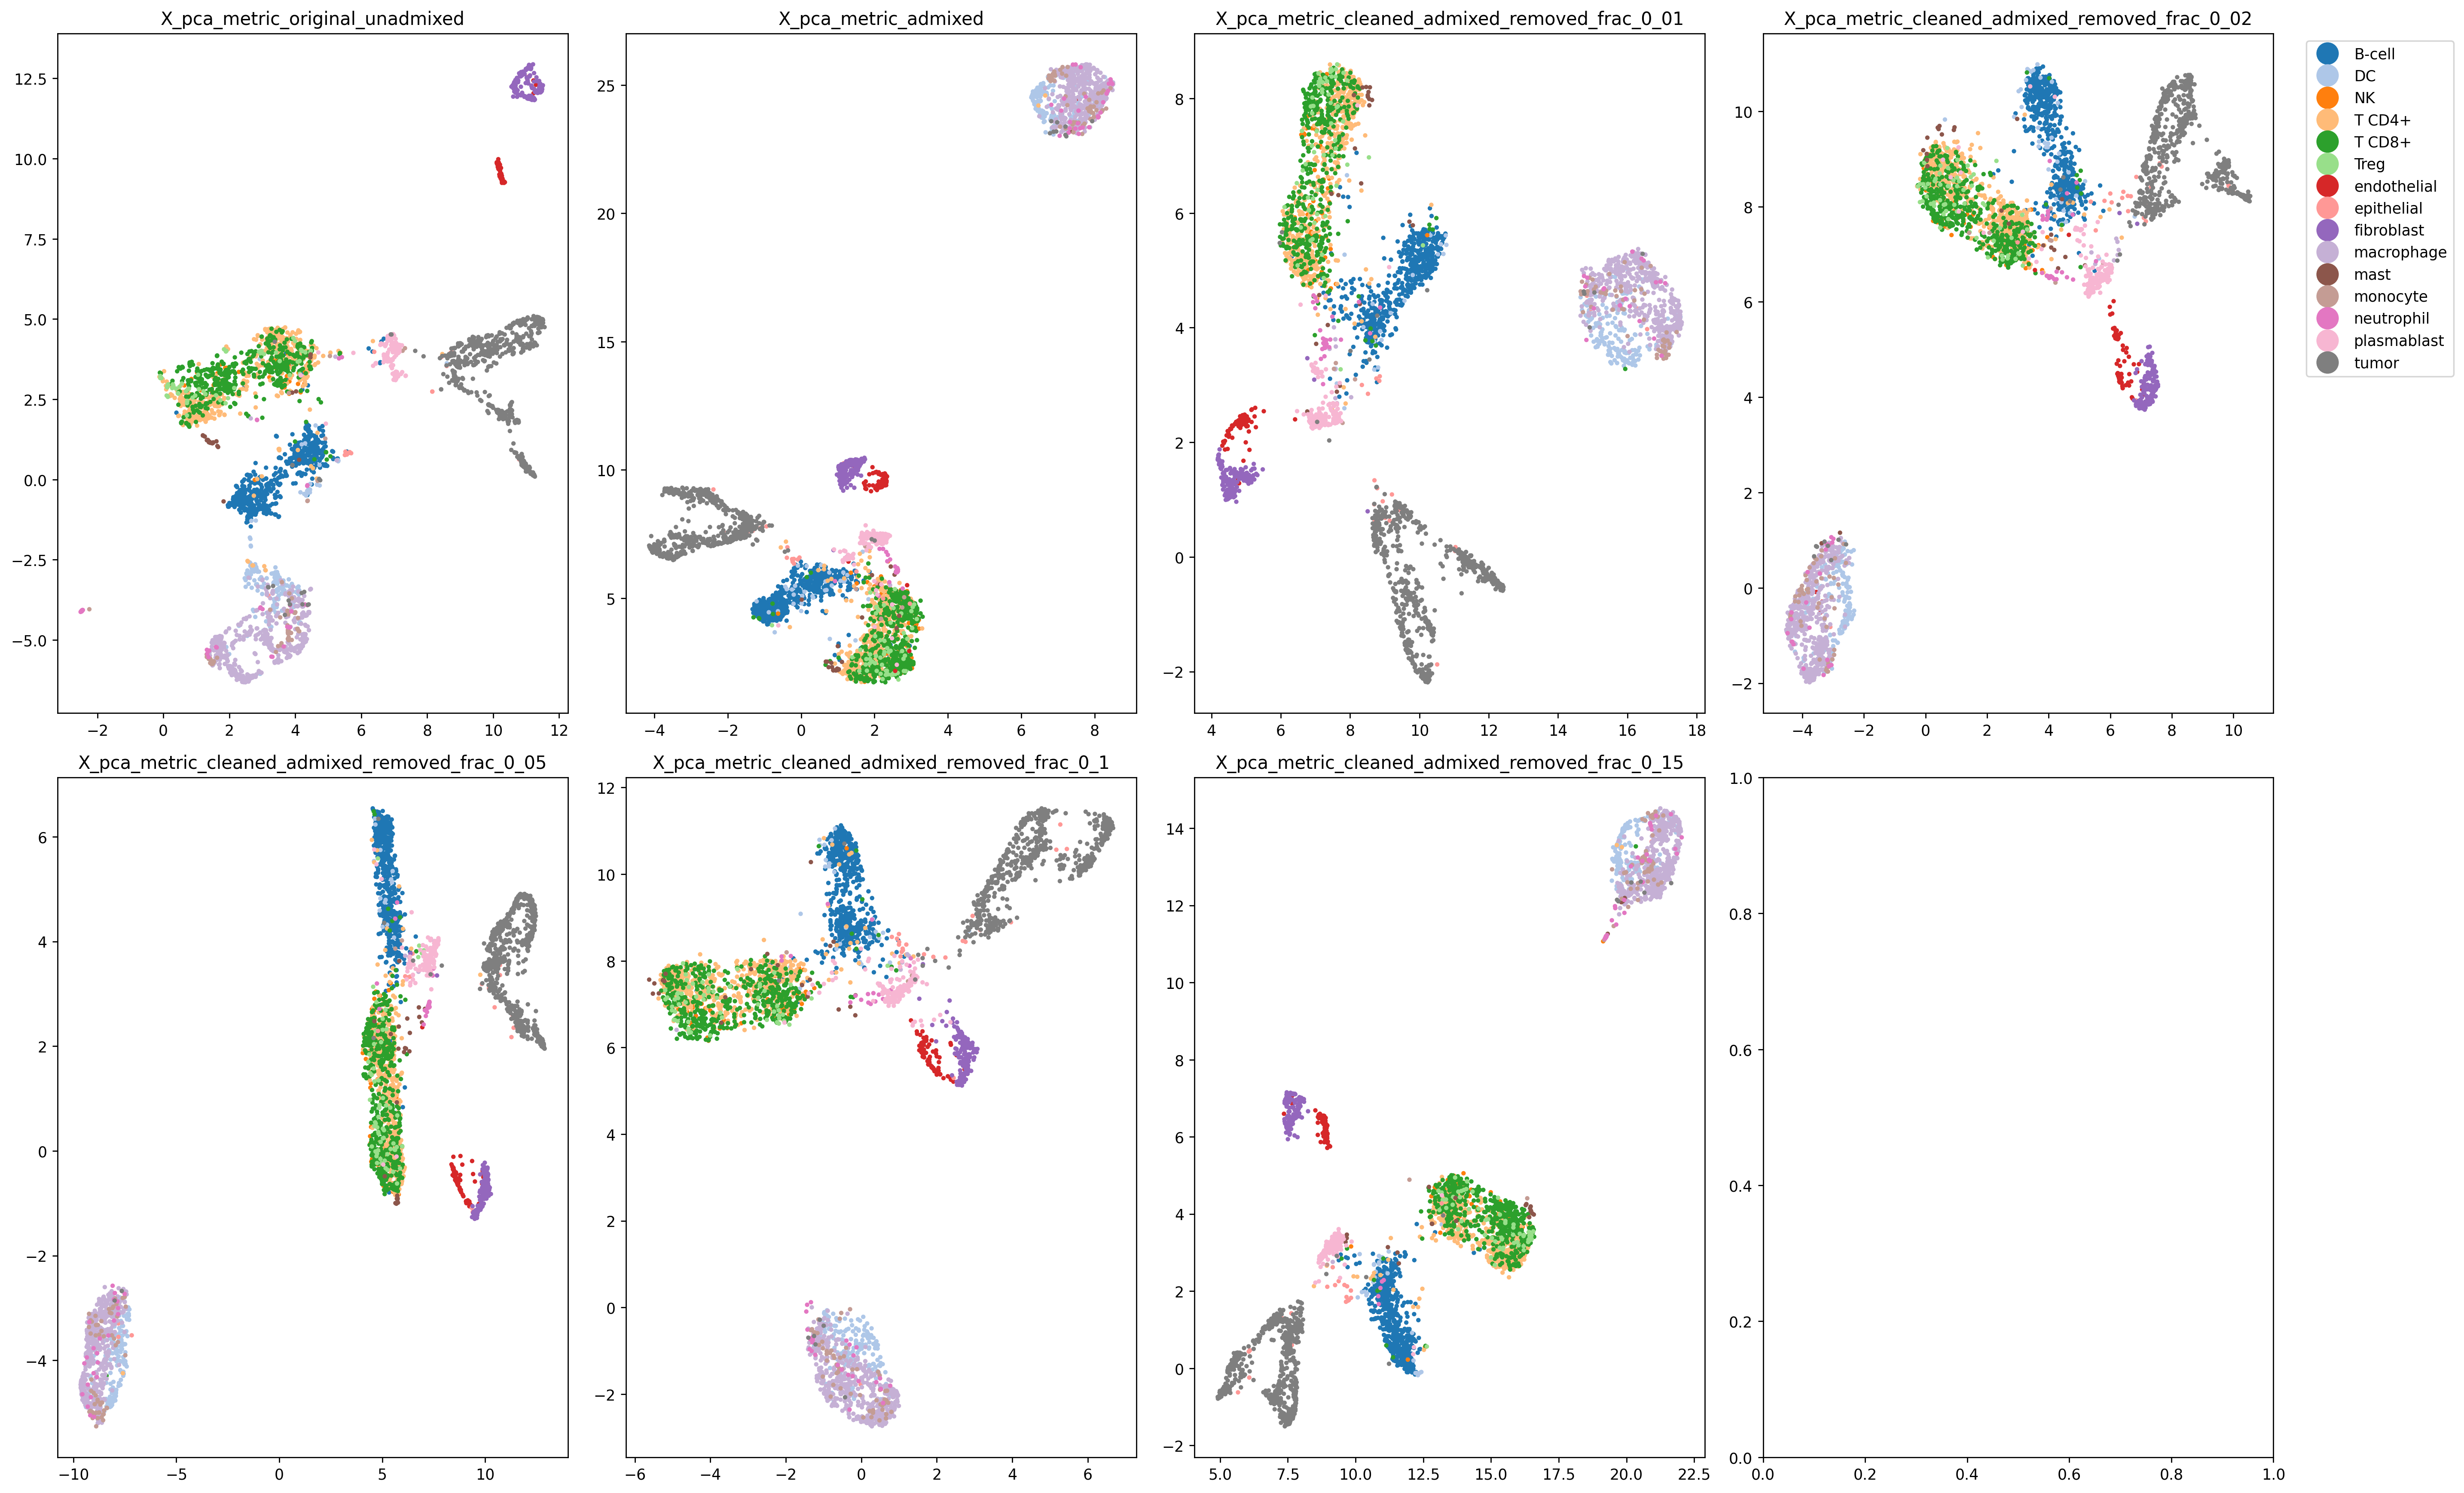

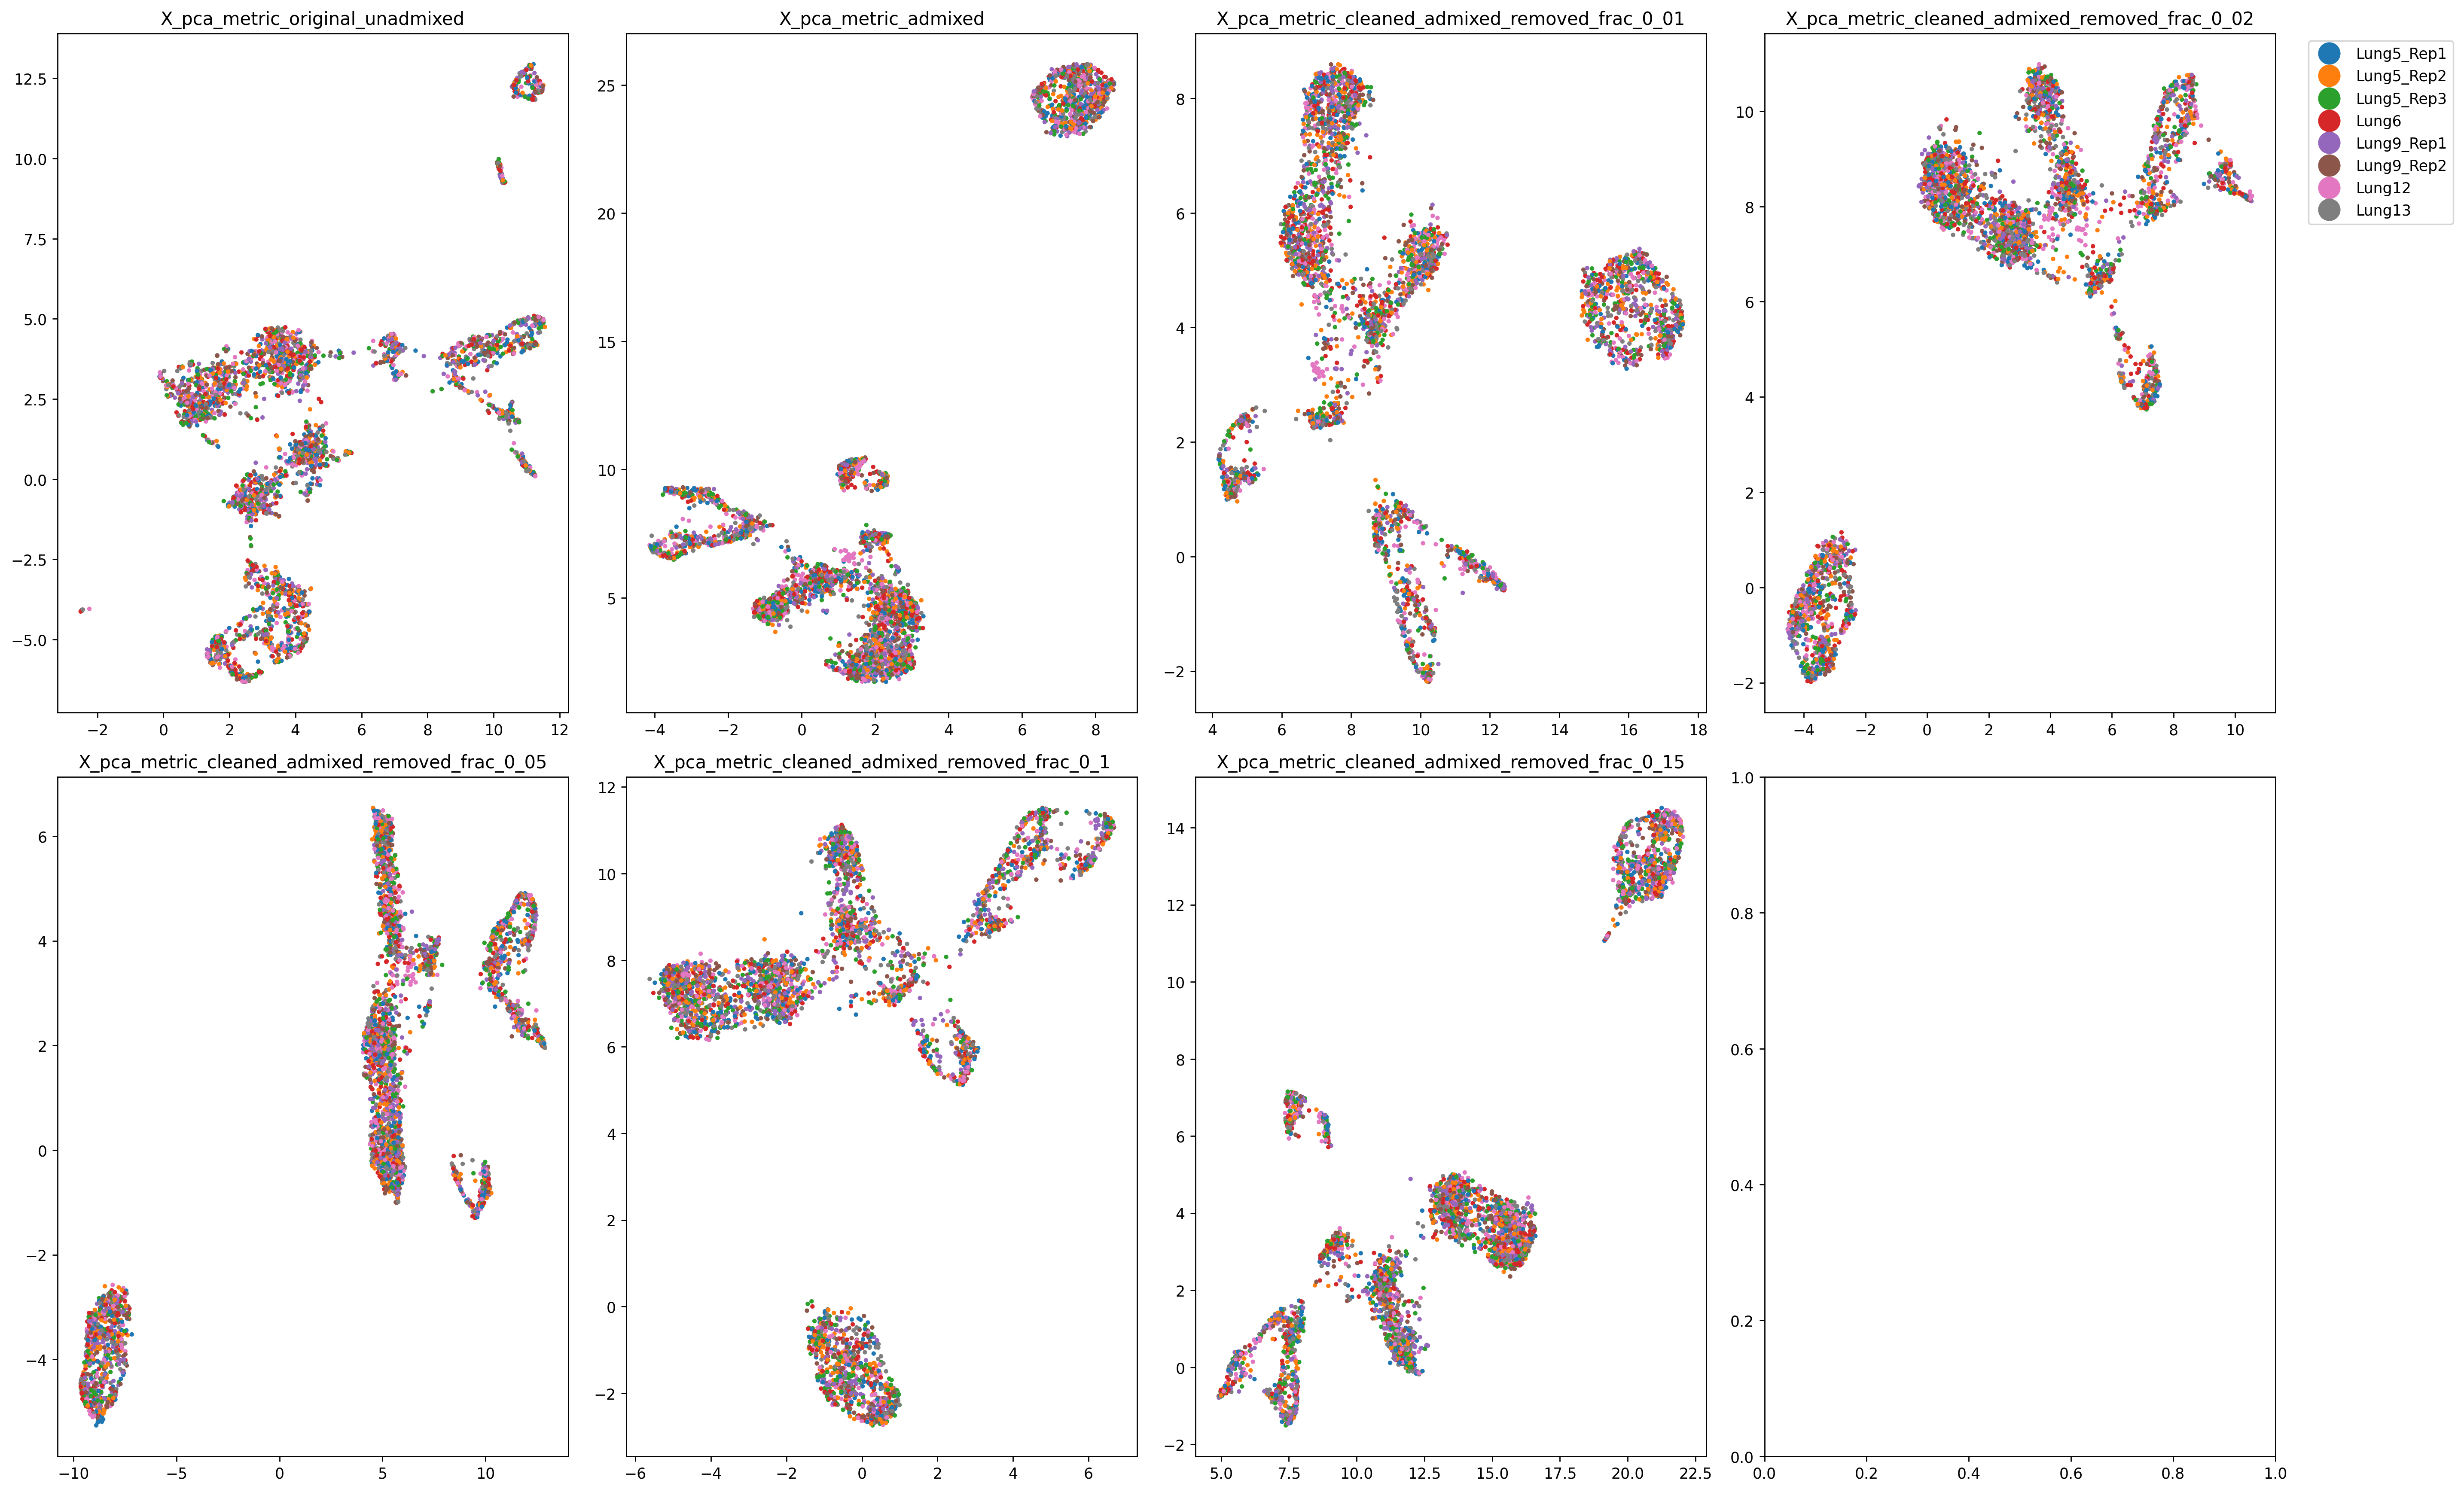

In [110]:
from umap import UMAP
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

settings = list(metrics_adata.obsm.keys())[1:]

tissue_subset = [
    t for t in sc_data.obs["harmony_spatial_tissue"].unique().tolist()
    # if t.startswith("Lung5")
]

plot_data = {}

for setting in settings:
    mask = (
        (np.sum(np.isnan(metrics_adata.obsm[setting]), axis=1) == 0)
        & (metrics_adata.obs["harmony_spatial_tissue"].isin(tissue_subset).to_numpy())
    )

    set_adata = metrics_adata[mask]
    set_adata = set_adata[set_adata.obs.groupby('cell_type').sample(frac=0.1).index]
    coords = UMAP().fit_transform(set_adata.obsm[setting])

    plot_data[setting] = {
        "adata": set_adata,
        "coords": coords,
    }


def plot_umap_panels(
    color_by,
    palette=None,
    highlight_neutrophils=False,
    neutrophil_col="cell_type",
    neutrophil_label="neutrophil",
):
    fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(23, 14), dpi=250)

    for i, setting in enumerate(settings):
        ax = axes.flat[i]
        set_adata = plot_data[setting]["adata"]
        coords = plot_data[setting]["coords"]

        legend = i == 3

        if highlight_neutrophils:
            neutrophil_mask = (
                set_adata.obs[neutrophil_col]
                .astype(str)
                .str.lower()
                .eq(neutrophil_label.lower())
                .to_numpy()
            )

            ax.scatter(
                coords[~neutrophil_mask, 0],
                coords[~neutrophil_mask, 1],
                s=4,
                c="lightgray",
                alpha=0.25,
                linewidths=0,
                rasterized=True,
            )

            sns.scatterplot(
                x=coords[neutrophil_mask, 0],
                y=coords[neutrophil_mask, 1],
                hue=set_adata.obs.loc[neutrophil_mask, color_by],
                s=12,
                ax=ax,
                legend=legend,
                palette=palette,
                linewidth=0,
                rasterized=True,
            )

        else:
            sns.scatterplot(
                x=coords[:, 0],
                y=coords[:, 1],
                hue=set_adata.obs[color_by],
                s=9,
                ax=ax,
                legend=legend,
                palette=palette,
                linewidth=0,
                rasterized=True,
            )

        ax.set_title(setting)

        if legend:
            ax.legend(bbox_to_anchor=(1.05, 1), markerscale=5)

    fig.tight_layout()
    return fig, axes

fig_cell_type, axes_cell_type = plot_umap_panels(
    color_by="Major cell type",
    palette="tab20",
    highlight_neutrophils=False,
)

fig_tissue, axes_tissue = plot_umap_panels(
    color_by="cell_type",
    palette="tab20",
    highlight_neutrophils=False,
)

fig_tissue, axes_tissue = plot_umap_panels(
    color_by="harmony_spatial_tissue",
    highlight_neutrophils=False,
)

In [74]:
metrics_adata.layers

Layers with keys: admix_probs, admixed_counts

Text(0.5, 1.0, 'Admix Probabilities (for probs > 0)')

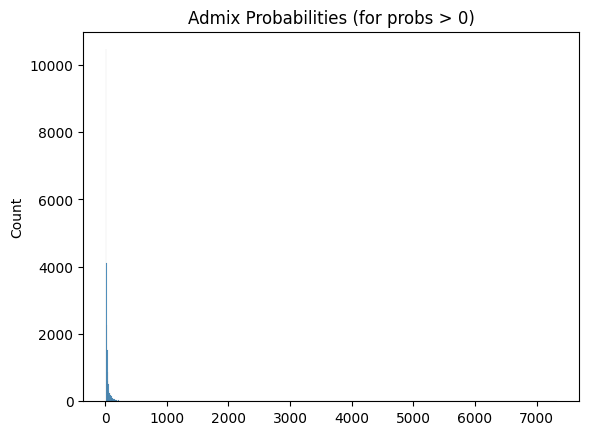

In [79]:
probs=metrics_adata.layers['admix_probs'].toarray().flatten()
counts=metrics_adata.layers['admixed_counts'].toarray().flatten()
probs=probs[probs>0]
counts=counts[counts>10]

ax = sns.histplot(counts,bins=1000)
ax.set_title('Admix Probabilities (for probs > 0)')

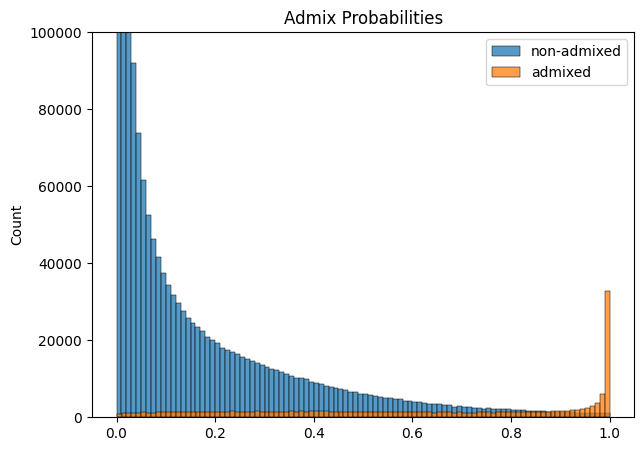

In [111]:
probs=metrics_adata.layers['admix_probs'].toarray().flatten()
raw_counts=metrics_adata.X.toarray().flatten()
admix_counts = metrics_adata.layers['admixed_counts'].toarray().flatten()

nonadmix_probs=probs[(admix_counts==0)&(raw_counts>0)]
admix_probs=probs[(admix_counts>0)]
fig,ax = plt.subplots(figsize=(7,5))

ax = sns.histplot(nonadmix_probs,bins=100,ax=ax,label='non-admixed')
ax = sns.histplot(admix_probs,bins=100,ax=ax,label='admixed')
ax.set_ylim([0,100000])
ax.set_title('Admix Probabilities')
ax.legend()

/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/IPython/core/events.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


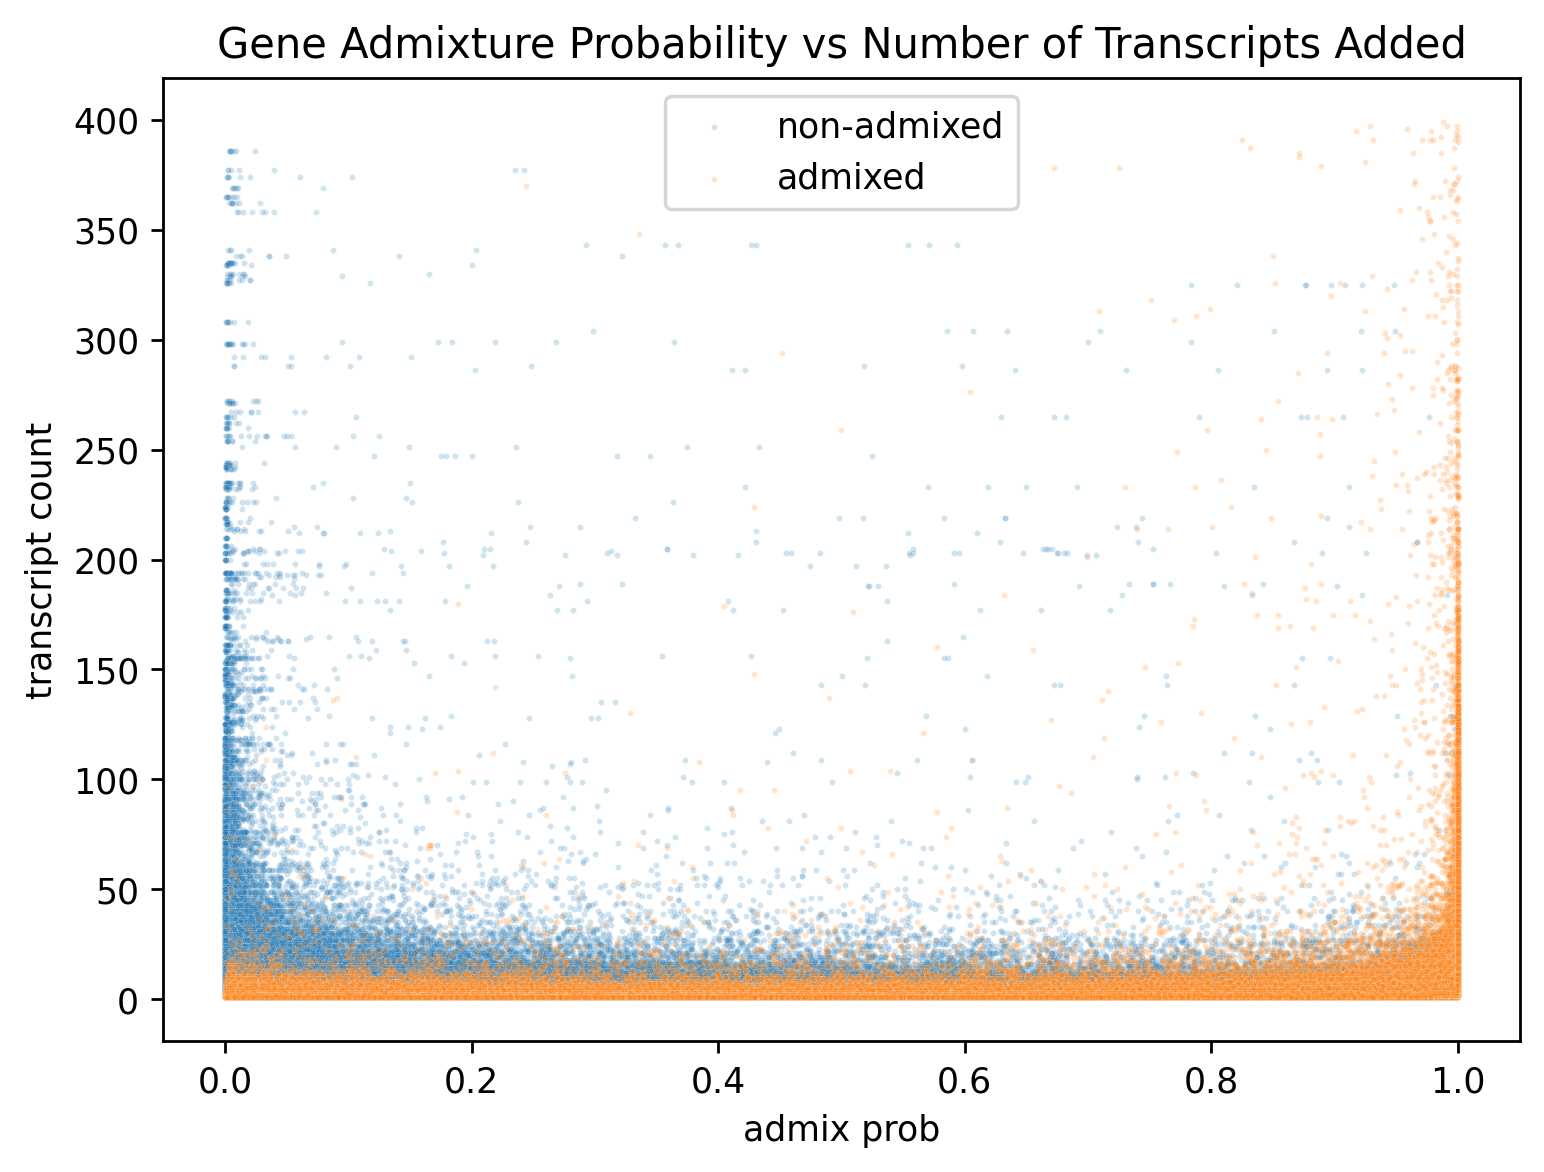

In [112]:
probs=metrics_adata.layers['admix_probs'].toarray().flatten()
raw_counts=metrics_adata.X.toarray().flatten()
admix_counts = metrics_adata.layers['admixed_counts'].toarray().flatten()
counts = raw_counts+admix_counts
nonadmix_probs=probs[(admix_counts==0)&(raw_counts>0)]
admix_probs=probs[(admix_counts>0)]

fig,ax = plt.subplots(figsize=(7,5),dpi=250)
ax = sns.scatterplot(x=nonadmix_probs,y=counts[(admix_counts==0)&(raw_counts>0)],label='non-admixed',ax=ax,s=3,alpha=0.2)
ax = sns.scatterplot(x=admix_probs,y=counts[admix_counts>0],label='admixed',ax=ax,s=3,alpha=0.2)

ax.set_title("Gene Admixture Probability vs Number of Transcripts Added")
ax.set_xlabel("admix prob")
ax.set_ylabel("transcript count")
ax.legend()